In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import GridSearchCV

In [5]:
train_df = pd.read_csv('D:\\Data science\\Assignments\\Answers\\XGBM & LGBM\\XGBM & LGBM\\Titanic_train.csv')
display(train_df.head())
display(train_df.info())

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


None

In [6]:
train_df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

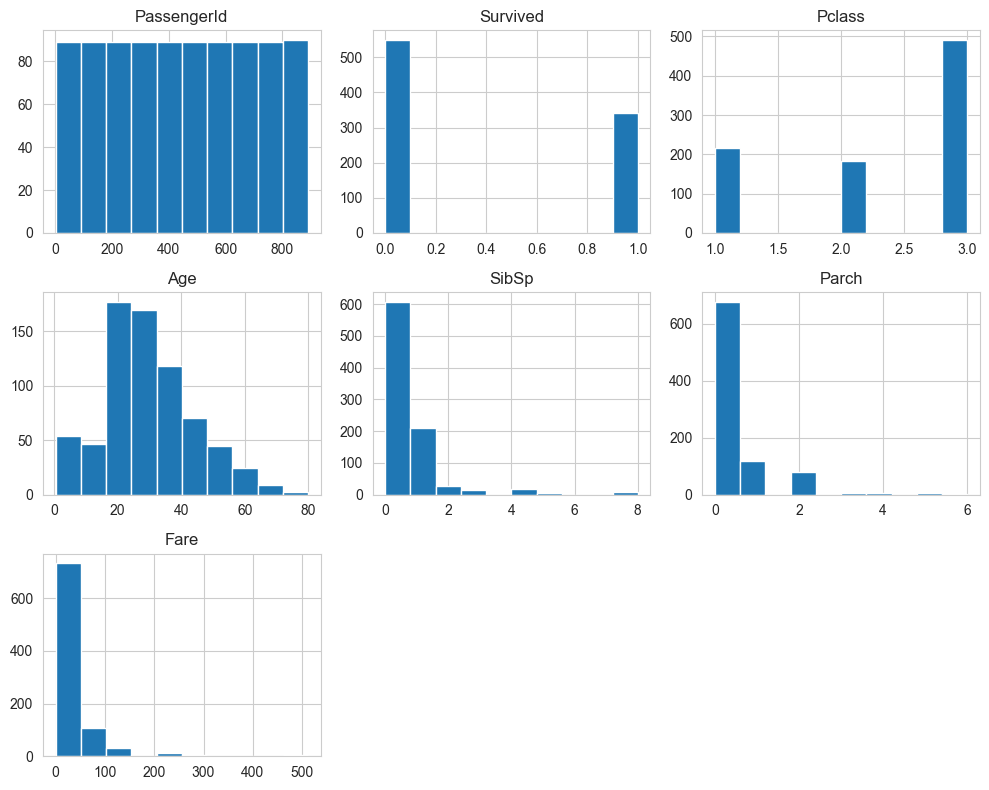

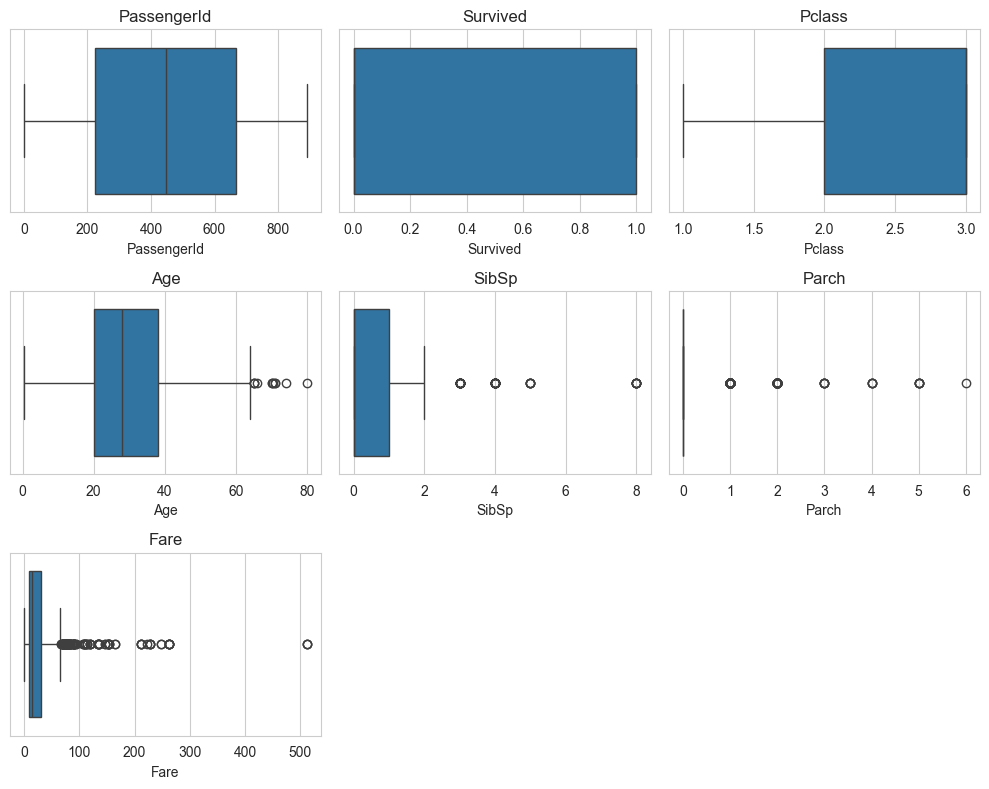

In [7]:
# Set the style for the plots
sns.set_style('whitegrid')

# Create histograms for numerical features
train_df.hist(figsize=(10, 8))
plt.tight_layout()
plt.show()

# Create box plots for numerical features
numerical_cols = train_df.select_dtypes(include=['float64', 'int64']).columns
plt.figure(figsize=(10, 8))
for i, col in enumerate(numerical_cols):
    plt.subplot(3, 3, i + 1)
    sns.boxplot(x=train_df[col], orient='h')
    plt.title(col)
plt.tight_layout()
plt.show()

In [8]:
train_df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


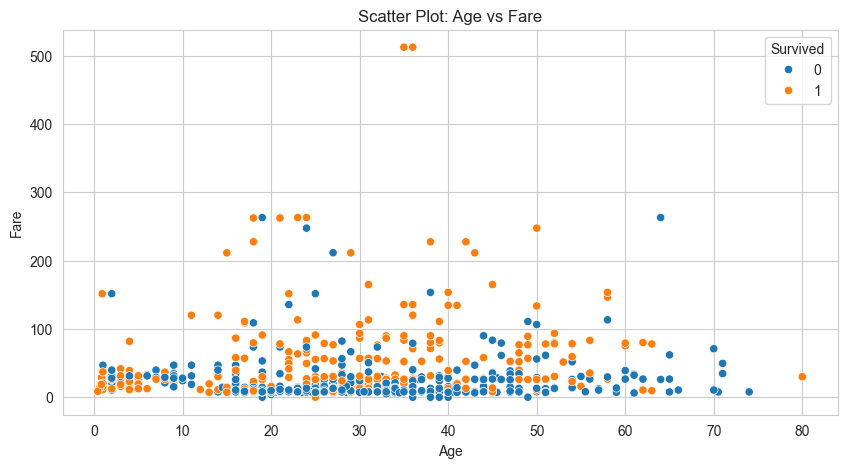

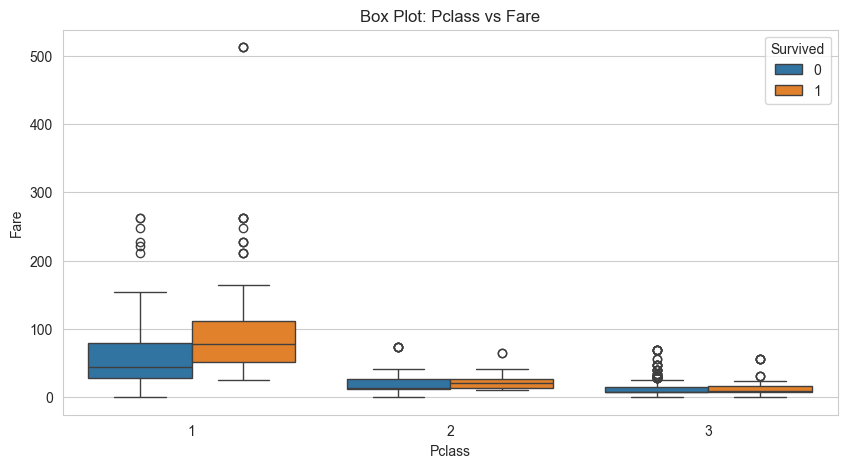

In [9]:
# Scatter plot: Age vs Fare
plt.figure(figsize=(10, 5))
sns.scatterplot(data=train_df, x='Age', y='Fare', hue='Survived')
plt.title('Scatter Plot: Age vs Fare')
plt.xlabel('Age')
plt.ylabel('Fare')
plt.legend(title='Survived')
plt.show()
# Box plot: Pclass vs Fare
plt.figure(figsize=(10, 5))
sns.boxplot(data=train_df, x='Pclass', y='Fare', hue='Survived')
plt.title('Box Plot: Pclass vs Fare')
plt.xlabel('Pclass')
plt.ylabel('Fare')
plt.legend(title='Survived')
plt.show()

In [10]:
# Impute missing values in 'Age' with the median age
median_age = train_df['Age'].median()
train_df['Age'].fillna(median_age, inplace=True)
display(train_df.isnull().sum())

# Impute missing values in 'Embarked' with the mode
most_frequent_embarked = train_df['Embarked'].mode()[0]
train_df['Embarked'].fillna(most_frequent_embarked, inplace=True)
display(train_df.isnull().sum())

# Drop the 'Cabin' column due to a large number of missing values
train_df.drop('Cabin', axis=1, inplace=True)
display(train_df.isnull().sum())

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age              0
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age              0
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         0
dtype: int64

PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
dtype: int64

In [11]:
# Initialize LabelEncoder
label_encoder = LabelEncoder()

# Apply LabelEncoder to the categorical columns
for col in ['Sex', 'Embarked', 'Pclass']:
    train_df[col] = label_encoder.fit_transform(train_df[col])

# Display the first few rows of the modified DataFrame to show the encoded columns
print("First 5 rows after label encoding:")
display(train_df.head())

First 5 rows after label encoding:


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked
0,1,0,2,"Braund, Mr. Owen Harris",1,22.0,1,0,A/5 21171,7.2500,2
1,2,1,0,"Cumings, Mrs. John Bradley (Florence Briggs Th...",0,38.0,1,0,PC 17599,71.2833,0
2,3,1,2,"Heikkinen, Miss. Laina",0,26.0,0,0,STON/O2. 3101282,7.9250,2
3,4,1,0,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",0,35.0,1,0,113803,53.1000,2
4,5,0,2,"Allen, Mr. William Henry",1,35.0,0,0,373450,8.0500,2


In [12]:
X = train_df.drop(['Name', 'Ticket', 'Survived', 'PassengerId'], axis=1)
y = train_df['Survived']

print("Shape of X:", X.shape)
print("Shape of y:", y.shape)

Shape of X: (891, 7)
Shape of y: (891,)


In [13]:
from sklearn.model_selection import train_test_split

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Print the shapes of the training and testing sets
print("Shape of X_train:", X_train.shape)
print("Shape of X_test:", X_test.shape)
print("Shape of y_train:", y_train.shape)
print("Shape of y_test:", y_test.shape)

Shape of X_train: (712, 7)
Shape of X_test: (179, 7)
Shape of y_train: (712,)
Shape of y_test: (179,)


In [14]:
import lightgbm as lgb
import xgboost as xgb

# Initialize and train LightGBM model
lgbm_model = lgb.LGBMClassifier(random_state=42)
lgbm_model.fit(X_train, y_train)

# Initialize and train XGBoost model
xgboost_model = xgb.XGBClassifier(random_state=42)
xgboost_model.fit(X_train, y_train)

print("LightGBM model trained successfully!")
print("XGBoost model trained successfully!")

[LightGBM] [Info] Number of positive: 268, number of negative: 444
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000698 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 193
[LightGBM] [Info] Number of data points in the train set: 712, number of used features: 7
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.376404 -> initscore=-0.504838
[LightGBM] [Info] Start training from score -0.504838
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf


In [15]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Make predictions on the test set
lgbm_pred = lgbm_model.predict(X_test)
xgboost_pred = xgboost_model.predict(X_test)

# Evaluate LightGBM model
lgbm_accuracy = accuracy_score(y_test, lgbm_pred)
lgbm_precision = precision_score(y_test, lgbm_pred)
lgbm_recall = recall_score(y_test, lgbm_pred)
lgbm_f1 = f1_score(y_test, lgbm_pred)

print("LightGBM Model Evaluation:")
print(f"Accuracy: {lgbm_accuracy:.4f}")
print(f"Precision: {lgbm_precision:.4f}")
print(f"Recall: {lgbm_recall:.4f}")
print(f"F1-score: {lgbm_f1:.4f}")

print("\nXGBoost Model Evaluation:")
# Evaluate XGBoost model
xgboost_accuracy = accuracy_score(y_test, xgboost_pred)
xgboost_precision = precision_score(y_test, xgboost_pred)
xgboost_recall = recall_score(y_test, xgboost_pred)
xgboost_f1 = f1_score(y_test, xgboost_pred)

print(f"Accuracy: {xgboost_accuracy:.4f}")
print(f"Precision: {xgboost_precision:.4f}")
print(f"Recall: {xgboost_recall:.4f}")
print(f"F1-score: {xgboost_f1:.4f}")

LightGBM Model Evaluation:
Accuracy: 0.8212
Precision: 0.7838
Recall: 0.7838
F1-score: 0.7838

XGBoost Model Evaluation:
Accuracy: 0.7989
Precision: 0.7568
Recall: 0.7568
F1-score: 0.7568


In [32]:
# Load the test dataset
test_df = pd.read_csv('D:\\Data science\\Assignments\\Answers\\XGBM & LGBM\\XGBM & LGBM\\Titanic_test.csv')

# Display the first few rows
print("First 5 rows of the test data:")
display(test_df.head())

# Print the shape of the DataFrame
print("\nShape of the test data:", test_df.shape)

First 5 rows of the test data:


,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,892,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,NaN,Q
1,893,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,NaN,S
2,894,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,240276,9.6875,NaN,Q
3,895,3,"Wirz, Mr. Albert",male,27.0,0,0,315154,8.6625,NaN,S
4,896,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.0,1,1,3101298,12.2875,NaN,S



Shape of the test data: (418, 11)


In [33]:
from sklearn.preprocessing import LabelEncoder

# Impute missing values in 'Age' with the median age from the training data
median_age = test_df['Age'].median()
test_df['Age'].fillna(median_age, inplace=True)

# Impute missing values in 'Fare' with the median fare from the training data
median_fare = train_df['Fare'].median()
test_df['Fare'].fillna(median_fare, inplace=True)

# Impute missing values in 'Embarked' with the mode from the training data
most_frequent_embarked = train_df['Embarked'].mode()[0]
test_df['Embarked'].fillna(most_frequent_embarked, inplace=True)

# Drop the 'Cabin' column if it exists
if 'Cabin' in test_df.columns:
    test_df.drop('Cabin', axis=1, inplace=True)

# Initialize a new LabelEncoder for the test data
test_label_encoder = LabelEncoder()

# Apply label encoding to the categorical columns in the test data
for col in ['Sex', 'Embarked', 'Pclass']:
    test_df[col] = test_label_encoder.fit_transform(test_df[col])

display(test_df.isnull().sum())
display(test_df.head())

PassengerId    0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
dtype: int64

,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked
0,892,2,"Kelly, Mr. James",1,34.5,0,0,330911,7.8292,1
1,893,2,"Wilkes, Mrs. James (Ellen Needs)",0,47.0,1,0,363272,7.0000,2
2,894,1,"Myles, Mr. Thomas Francis",1,62.0,0,0,240276,9.6875,1
3,895,2,"Wirz, Mr. Albert",1,27.0,0,0,315154,8.6625,2
4,896,2,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",0,22.0,1,1,3101298,12.2875,2


In [34]:
X_test_data = test_df.drop(['PassengerId', 'Name', 'Ticket'], axis=1)
print("Shape of X_test_data:", X_test_data.shape)

Shape of X_test_data: (418, 7)


In [35]:
# Make predictions on the preprocessed test data

test_predictions = xgboost_model.predict(X_test_data)
test_predictions_proba = xgboost_model.predict_proba(X_test_data)[:, 1]

print("Predictions on test data have been made.")
# You can now use 'test_predictions' or 'test_predictions_proba' for submission or further analysis.
display(test_predictions_proba)
display(test_predictions)

Predictions on test data have been made.


array([1.72541179e-02, 6.05101399e-02, 2.29425967e-01, 5.73001444e-01,
       6.60314023e-01, 6.35935962e-02, 5.78609586e-01, 3.82040557e-03,
       9.74136949e-01, 8.55036825e-03, 1.99895650e-01, 8.17348883e-02,
       9.92881417e-01, 4.23466116e-02, 9.87772405e-01, 9.82056737e-01,
       9.31136608e-02, 6.80881202e-01, 6.56021655e-01, 4.30014461e-01,
       4.23944294e-01, 1.13678642e-01, 9.74961638e-01, 6.09609902e-01,
       9.42813456e-01, 1.89641374e-03, 9.99810517e-01, 5.33281028e-01,
       7.02615499e-01, 2.38204181e-01, 2.20529605e-02, 3.17278691e-02,
       3.95912379e-01, 1.66227780e-02, 8.52344990e-01, 1.56768441e-01,
       4.72163409e-01, 1.81159656e-02, 1.34284571e-02, 8.98055971e-01,
       2.84942482e-02, 8.38554382e-01, 7.13693947e-02, 9.90613222e-01,
       9.90530908e-01, 6.84532747e-02, 6.08346388e-02, 7.30463505e-01,
       9.99293804e-01, 9.42929149e-01, 9.78769362e-02, 6.60844520e-02,
       9.94741917e-01, 8.46087754e-01, 2.75249273e-01, 1.50632218e-03,
      

array([0, 0, 0, 1, 1, 0, 1, 0, 1, 0, 0, 0, 1, 0, 1, 1, 0, 1, 1, 0, 0, 0,
       1, 1, 1, 0, 1, 1, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 1, 0, 1,
       1, 0, 0, 1, 1, 1, 0, 0, 1, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0,
       0, 0, 0, 1, 1, 0, 1, 0, 1, 1, 0, 1, 0, 1, 1, 0, 0, 0, 1, 0, 1, 1,
       1, 1, 0, 1, 1, 0, 0, 0, 1, 0, 0, 0, 1, 0, 1, 0, 1, 0, 0, 1, 1, 0,
       0, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 0, 1, 0, 0, 0, 0,
       0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 1, 0, 1, 1, 0, 1,
       0, 0, 1, 0, 1, 0, 1, 1, 1, 1, 0, 0, 0, 0, 1, 0, 1, 1, 0, 1, 0, 1,
       1, 1, 1, 1, 0, 1, 1, 1, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0,
       0, 1, 1, 1, 0, 1, 0, 0, 0, 0, 1, 0, 0, 1, 0, 1, 0, 0, 1, 0, 1, 0,
       1, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 1, 1, 0, 1, 1, 1, 1, 0, 1,
       0, 0, 0, 0, 1, 0, 1, 0, 1, 1, 0, 0, 0, 1, 1, 0, 1, 0, 0, 0, 1, 1,
       0, 0, 1, 1, 0, 0, 0, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 1, 1, 1, 0, 0,
       1, 0, 1, 0, 0, 1, 1, 0, 0, 0, 1, 0, 0, 0, 0,

### Grid searchCV

In [16]:
# Define the hyperparameter grid for LightGBM
lgbm_param_grid = {
    'n_estimators': [100, 200, 300],
    'learning_rate': [0.01, 0.05, 0.1],
    'num_leaves': [31, 50, 70],
    'max_depth': [-1, 10, 20]
}

# Define the hyperparameter grid for XGBoost
xgboost_param_grid = {
    'n_estimators': [100, 200, 300],
    'learning_rate': [0.01, 0.05, 0.1],
    'max_depth': [3, 5, 7],
    'subsample': [0.6, 0.8, 1.0]
}

print("LightGBM hyperparameter grid defined:")
print(lgbm_param_grid)
print("\nXGBoost hyperparameter grid defined:")
print(xgboost_param_grid)

LightGBM hyperparameter grid defined:
{'n_estimators': [100, 200, 300], 'learning_rate': [0.01, 0.05, 0.1], 'num_leaves': [31, 50, 70], 'max_depth': [-1, 10, 20]}

XGBoost hyperparameter grid defined:
{'n_estimators': [100, 200, 300], 'learning_rate': [0.01, 0.05, 0.1], 'max_depth': [3, 5, 7], 'subsample': [0.6, 0.8, 1.0]}


In [17]:
from sklearn.model_selection import StratifiedKFold

# Instantiate StratifiedKFold for cross-validation
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

print("Stratified K-Fold cross-validation strategy defined with 5 splits.")

Stratified K-Fold cross-validation strategy defined with 5 splits.


In [18]:
# Initialize GridSearchCV for LightGBM
lgbm_grid_search = GridSearchCV(estimator=lgbm_model, param_grid=lgbm_param_grid, cv=cv, scoring='accuracy', n_jobs=-1)

# Fit GridSearchCV for LightGBM
lgbm_grid_search.fit(X_train, y_train)

# Initialize GridSearchCV for XGBoost
xgboost_grid_search = GridSearchCV(estimator=xgboost_model, param_grid=xgboost_param_grid, cv=cv, scoring='accuracy', n_jobs=-1)

# Fit GridSearchCV for XGBoost
xgboost_grid_search.fit(X_train, y_train)

# Print the best parameters and best scores for LightGBM
print("LightGBM Best Parameters:", lgbm_grid_search.best_params_)
print("LightGBM Best Score:", lgbm_grid_search.best_score_)

# Print the best parameters and best scores for XGBoost
print("XGBoost Best Parameters:", xgboost_grid_search.best_params_)
print("XGBoost Best Score:", xgboost_grid_search.best_score_)

[LightGBM] [Info] Number of positive: 268, number of negative: 444
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000178 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 193
[LightGBM] [Info] Number of data points in the train set: 712, number of used features: 7
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.376404 -> initscore=-0.504838
[LightGBM] [Info] Start training from score -0.504838
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf


In [27]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Extract the best models
best_lgbm_model = lgbm_grid_search.best_estimator_
best_xgboost_model = xgboost_grid_search.best_estimator_

# Make predictions on the test set
best_lgbm_pred = best_lgbm_model.predict(X_test)
best_xgboost_pred = best_xgboost_model.predict(X_test)

# Evaluate the best LightGBM model
best_lgbm_accuracy = accuracy_score(y_test, best_lgbm_pred)
best_lgbm_precision = precision_score(y_test, best_lgbm_pred)
best_lgbm_recall = recall_score(y_test, best_lgbm_pred)
best_lgbm_f1 = f1_score(y_test, best_lgbm_pred)

print("Tuned LightGBM Model Evaluation:")
print(f"Accuracy: {best_lgbm_accuracy:.4f}")
print(f"Precision: {best_lgbm_precision:.4f}")
print(f"Recall: {best_lgbm_recall:.4f}")
print(f"F1-score: {best_lgbm_f1:.4f}")

# Evaluate the best XGBoost model
best_xgboost_accuracy = accuracy_score(y_test, best_xgboost_pred)
best_xgboost_precision = precision_score(y_test, best_xgboost_pred)
best_xgboost_recall = recall_score(y_test, best_xgboost_pred)
best_xgboost_f1 = f1_score(y_test, best_xgboost_pred)

print("\nTuned XGBoost Model Evaluation:")
print(f"Accuracy: {best_xgboost_accuracy:.4f}")
print(f"Precision: {best_xgboost_precision:.4f}")
print(f"Recall: {best_xgboost_recall:.4f}")
print(f"F1-score: {best_xgboost_f1:.4f}")

Tuned LightGBM Model Evaluation:
Accuracy: 0.8156
Precision: 0.8060
Recall: 0.7297
F1-score: 0.7660

Tuned XGBoost Model Evaluation:
Accuracy: 0.8212
Precision: 0.8000
Recall: 0.7568
F1-score: 0.7778


In [28]:
print("Comparison of Tuned Model Performance:")
print("-" * 40)
print(f"Metric        | Tuned LightGBM | Tuned XGBoost")
print("-" * 40)
print(f"Accuracy      | {best_lgbm_accuracy:.4f}         | {best_xgboost_accuracy:.4f}")
print(f"Precision     | {best_lgbm_precision:.4f}         | {best_xgboost_precision:.4f}")
print(f"Recall        | {best_lgbm_recall:.4f}         | {best_xgboost_recall:.4f}")
print(f"F1-score      | {best_lgbm_f1:.4f}         | {best_xgboost_f1:.4f}")
print("-" * 40)

print("\nAnalysis:")
if best_xgboost_accuracy > best_lgbm_accuracy:
    print("XGBoost has slightly higher Accuracy.")
else:
    print("LightGBM has slightly higher Accuracy.")

if best_xgboost_precision > best_lgbm_precision:
     print("XGBoost has slightly higher Precision.")
else:
     print("LightGBM has slightly higher Precision.")

if best_xgboost_recall > best_lgbm_recall:
     print("XGBoost has slightly higher Recall.")
else:
     print("LightGBM has slightly higher Recall.")

if best_xgboost_f1 > best_lgbm_f1:
     print("XGBoost has slightly higher F1-score.")
else:
     print("LightGBM has slightly higher F1-score.")

print("\nConclusion:")
print("In the context of predicting Titanic survival, both models perform similarly. XGBoost shows slightly better overall performance across all metrics.")

Comparison of Tuned Model Performance:
----------------------------------------
Metric        | Tuned LightGBM | Tuned XGBoost
----------------------------------------
Accuracy      | 0.8156         | 0.8212
Precision     | 0.8060         | 0.8000
Recall        | 0.7297         | 0.7568
F1-score      | 0.7660         | 0.7778
----------------------------------------

Analysis:
XGBoost has slightly higher Accuracy.
LightGBM has slightly higher Precision.
XGBoost has slightly higher Recall.
XGBoost has slightly higher F1-score.

Conclusion:
In the context of predicting Titanic survival, both models perform similarly. XGBoost shows slightly better overall performance across all metrics.


## Visualizing and Interpreting Model Performance

Based on the evaluation metrics from the previous step, we can compare the performance of the tuned LightGBM and XGBoost models.

| Metric    | Tuned LightGBM | Tuned XGBoost |
|-----------|----------------|---------------|
| Accuracy  | 0.8156     | 0.8212      |
| Precision | 0.8060     | 0.8000      |
| Recall    | 0.7297     | 0.7568      |
| F1-score  | 0.7660     | 0.7778      |

**Interpretation:**

*   **Accuracy:** XGBoost has a slightly higher accuracy, meaning it correctly predicts the outcome (survival or not) for a slightly larger percentage of passengers in the test set.
*   **Precision:** LightGBM has slightly higher precision. Precision is the ability of the model to return only relevant instances. In this context, it means that when the LightGBM model predicts a passenger will survive, it is slightly more likely to be correct compared to XGBoost.
*   **Recall:** XGBoost has slightly higher recall. Recall is the ability of the model to find all relevant instances. In this case, it means that XGBoost is slightly better at identifying all the passengers who actually survived.
*   **F1-score:** XGBoost has a slightly higher F1-score, which is the harmonic mean of precision and recall. This metric provides a balance between precision and recall and suggests that XGBoost has a slightly better overall performance when considering both false positives and false negatives.

**Strengths and Weaknesses:**

*   **LightGBM:** Strengths include slightly better precision, which is important if minimizing false positives (predicting survival for someone who didn't) is a higher priority.
*   **XGBoost:** Strengths include slightly better accuracy, recall, and F1-score, suggesting it is slightly better at correctly identifying survivors and has a better balance of precision and recall.

In this specific case, the differences in performance are quite small, indicating that both models are performing similarly well on this dataset after tuning.

## Summary:

### Data Analysis Key Findings

*   The best hyperparameters for LightGBM were found to be `{'learning_rate': 0.01, 'max_depth': -1, 'n_estimators': 300, 'num_leaves': 31}`, resulting in a cross-validation accuracy of approximately 0.823.
*   The best hyperparameters for XGBoost were found to be `{'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 200, 'subsample': 0.6}`, resulting in a cross-validation accuracy of approximately 0.836.
*   On the test set, the tuned LightGBM model achieved an accuracy of 0.8156, precision of 0.8060, recall of 0.7297, and F1-score of 0.7660.
*   On the test set, the tuned XGBoost model achieved an accuracy of 0.8212, precision of 0.8000, recall of 0.7568, and F1-score of 0.7778.
*   XGBoost slightly outperformed LightGBM on the test set in terms of Accuracy (0.8212 vs 0.8156), Recall (0.7568 vs 0.7297), and F1-score (0.7778 vs 0.7660), while LightGBM had slightly higher Precision (0.8060 vs 0.8000).

### Insights or Next Steps

*   While XGBoost showed slightly better performance across most metrics in this specific case, the difference is marginal. Further analysis, such as evaluating on different datasets or using different cross-validation strategies, could provide more robust insights into which model is generally better.
*   Exploring a wider range of hyperparameters or using more advanced tuning techniques (like RandomizedSearchCV or Bayesian Optimization) could potentially lead to further improvements in model performance for both LightGBM and XGBoost.
